# S1 · Gradients and cytoarchitectural classes

In [3]:
from pathlib import Path
import sys
base_path = next(
    p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (p / "CODE").is_dir() and (p / "DATA").is_dir()
)
sys.path.insert(0, str(Path(base_path) / 'CODE'))


In [4]:
import pandas as pd
import os

In [5]:
bb_path = f"{base_path}/DATA/cytoarchitecture/bb_gradient_df.csv"
von_economo = f"{base_path}/DATA/cytoarchitecture/parcel_cyto_df.csv"

In [6]:
network_path = f"{base_path}/RESULTS/discovery_dataset/hurst/dataframes/df_hurst_parcelwise_FIN_D4_modwt_1_5_padding_0_decimate_0_residuals_w_rest.csv"

output_path = f"{base_path}/FIGURES/supplementary/Fig_S1"
os.makedirs(output_path, exist_ok=True)

In [7]:
bb_gradient_df = pd.read_csv(bb_path)
von_economo_df = pd.read_csv(von_economo)
network_df = pd.read_csv(network_path)
network_df = network_df[["Parcel", "Network"]]
network_df.drop_duplicates(inplace=True)
networks = network_df["Network"]
bb_gradient_df['Network'] = networks
von_economo_df['Network'] = networks

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

# GLOBAL STYLE

sns.set_style("ticks")

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "axes.linewidth": 1.5,
})

network_labels = ["VIS", "SMN", "DAN", "VAN", "LIM", "CONT", "DMN"]

network_name_map = {
    "Vis": "VIS",
    "SomMot": "SMN",
    "DorsAttn": "DAN",
    "SalVentAttn": "VAN",
    "Limbic": "LIM",
    "Cont": "CONT",
    "Default": "DMN",
}

for df in (bb_gradient_df, von_economo_df):
    df["Network"] = df["Network"].replace(network_name_map)
    df["Network"] = pd.Categorical(
        df["Network"],
        categories=network_labels,
        ordered=True
    )

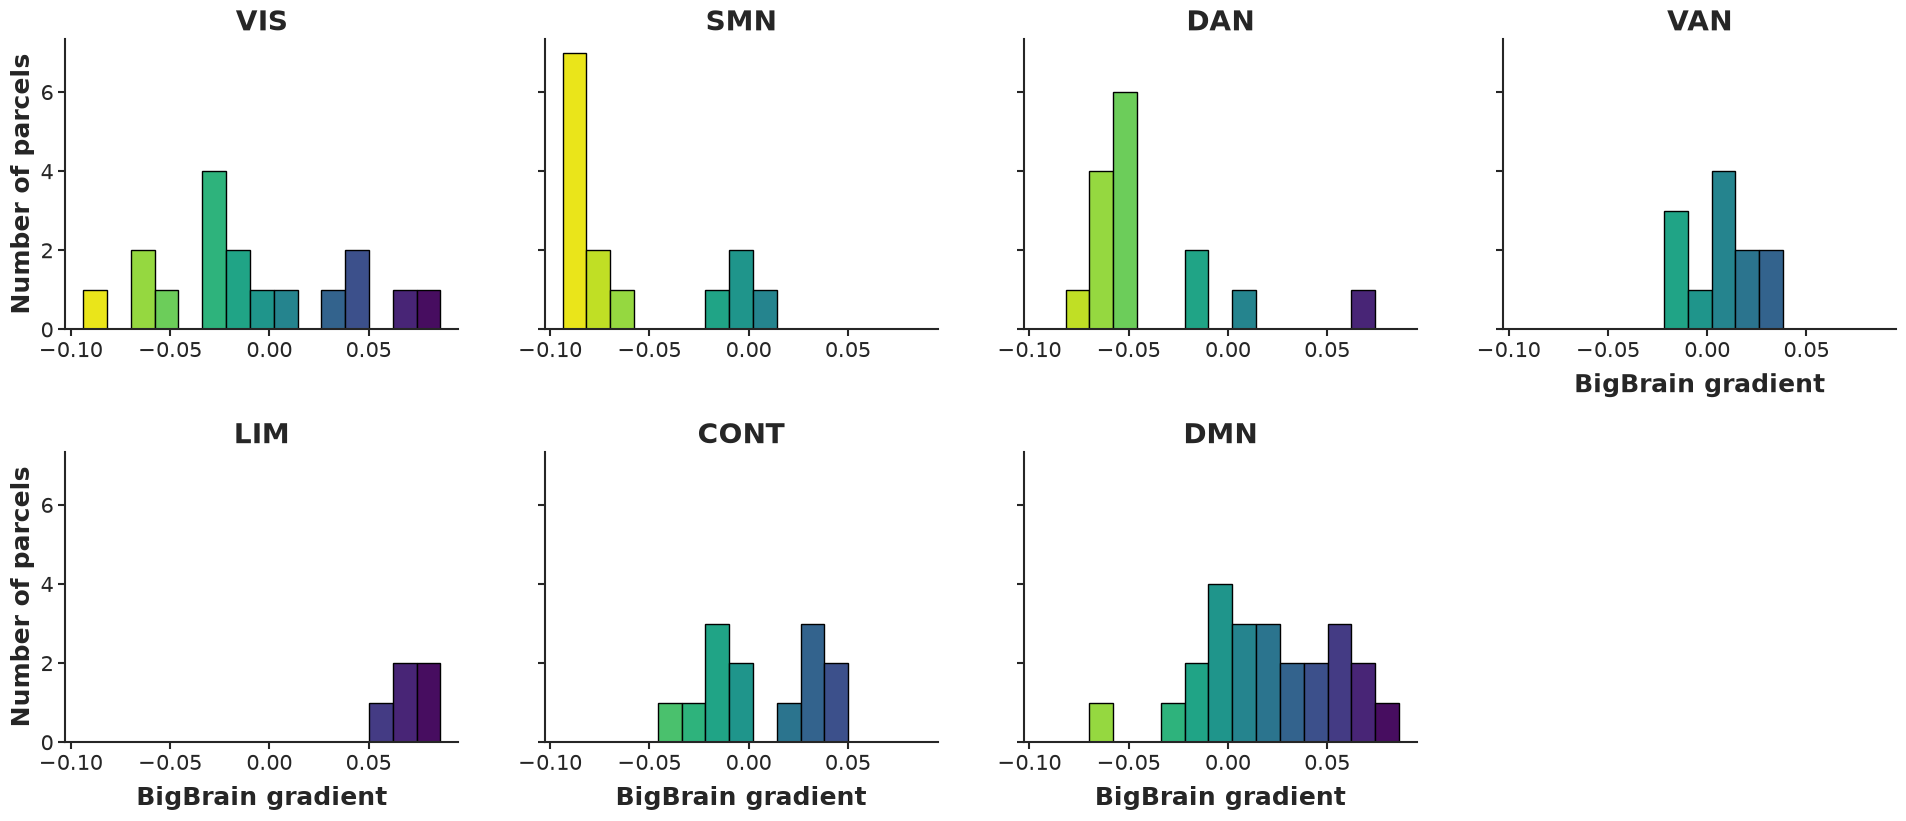

In [11]:
# 1. BIGBRAIN GRADIENT
x_col = "Cyto_class"

norm = mpl.colors.TwoSlopeNorm(
    vmin=bb_gradient_df[x_col].min(),
    vcenter=0,
    vmax=bb_gradient_df[x_col].max()
)

# negative = yellow, positive = purple
cmap = plt.cm.viridis_r

g = sns.displot(
    data=bb_gradient_df,
    x=x_col,
    col="Network",
    col_wrap=4,
    bins=15,
    kde=False,
    height=4.2,
    aspect=1.15,
    facet_kws={
        "sharex": True,
        "sharey": True
    },
    color="grey"
)

for ax in g.axes.flat:

    # color histogram bars by x position
    for patch in ax.patches:
        x_center = patch.get_x() + patch.get_width() / 2

        patch.set_facecolor(cmap(norm(x_center)))
        patch.set_edgecolor("black")
        patch.set_linewidth(1)

    # FORCE x ticks + labels on every row
    ax.tick_params(
        axis="x",
        which="both",
        bottom=True,
        labelbottom=True,
        labelsize=15,
        width=1.5,
        length=5
    )

    ax.tick_params(
        axis="y",
        labelsize=15,
        width=1.5,
        length=5
    )

    # x label on every subplot
    ax.set_xlabel(
        "BigBrain gradient",
        fontsize=18,
        fontweight="bold",
        labelpad=8
    )

    # thicker spines
    ax.spines["bottom"].set_linewidth(1.5)
    ax.spines["left"].set_linewidth(1.5)

    # remove upper/right border
    sns.despine(ax=ax)

# y label
g.set_ylabels(
    "Number of parcels",
    fontsize=18,
    fontweight="bold"
)

# network titles
g.set_titles(
    "{col_name}",
    size=20,
    weight="bold"
)

g.fig.subplots_adjust(
    hspace=0.42,
    wspace=0.22
)

plt.show()

g.savefig(
    f"{output_path}/bigbrain_gradient_by_network.png",
    dpi=300,
    bbox_inches="tight"
)

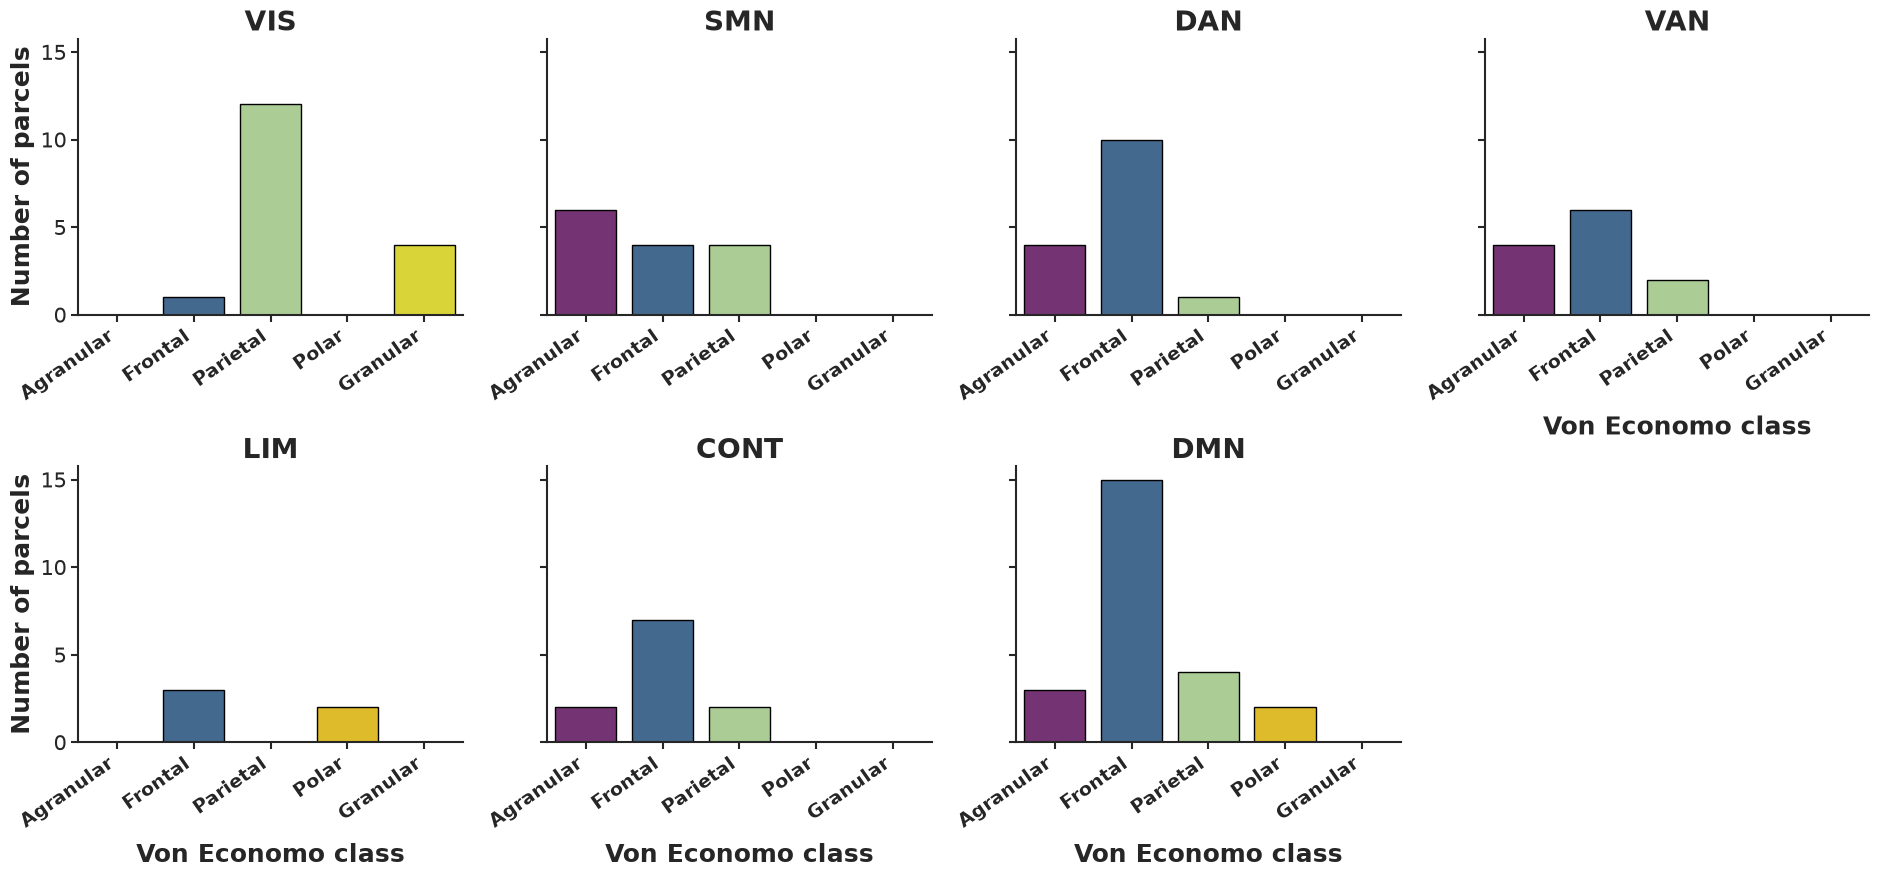

In [12]:
# 2. VON ECONOMO CLASSES
x_col = "Cyto_class"

class_names = {
    1: "Agranular",
    2: "Frontal",
    3: "Parietal",  
    4: "Polar",
    5: "Granular"
}

palette = {
    "Agranular": "#7f297e",
    "Frontal": "#37699c",
    "Parietal": "#aad58c",
    "Polar": "#fcce0c",
    "Granular": "#f4ee1d"
}

von_economo_df[x_col] = von_economo_df[x_col].astype(int)

von_economo_df["Cyto_name"] = (
    von_economo_df[x_col]
    .map(class_names)
)

order = [
    "Agranular",
    "Frontal",
    "Parietal",
    "Polar",
    "Granular"
]

g = sns.catplot(
    data=von_economo_df,
    x="Cyto_name",
    hue="Cyto_name",
    col="Network",
    col_wrap=4,
    kind="count",
    order=order,
    hue_order=order,
    palette=palette,
    height=4.2,
    aspect=1.15,
    edgecolor="black",
    linewidth=1,
    legend=False
)

for ax in g.axes.flat:

    # FORCE x ticks + labels on every row
    ax.tick_params(
        axis="x",
        which="both",
        bottom=True,
        labelbottom=True,
        labelsize=14,
        width=1.5,
        length=5,
        rotation=35
    )

    ax.tick_params(
        axis="y",
        labelsize=15,
        width=1.5,
        length=5
    )

    # bold tick labels
    for tick in ax.get_xticklabels():
        tick.set_fontweight("bold")
        tick.set_horizontalalignment("right")

    # x label on EVERY subplot
    ax.set_xlabel(
        "Von Economo class",
        fontsize=18,
        fontweight="bold",
        labelpad=8
    )

    sns.despine(ax=ax)

g.set_ylabels(
    "Number of parcels",
    fontsize=18,
    fontweight="bold"
)

g.set_titles(
    "{col_name}",
    size=20,
    weight="bold"
)

g.fig.subplots_adjust(
    hspace=0.55,
    wspace=0.22
)

plt.show()

g.savefig(
    f"{output_path}/von_economo_gradient_by_network.png",
    dpi=300,
    bbox_inches="tight"
)